In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

sns.set_theme(style="whitegrid")

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [6]:
data = df.copy()

data.drop(columns=["customerID"], inplace=True)

data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

data.drop_duplicates(inplace=True)

print("Cleaned dataset shape:", data.shape)
print("\nMissing values after cleaning:")
print(data.isnull().sum().sort_values(ascending=False).head())

Cleaned dataset shape: (7021, 20)

Missing values after cleaning:
TotalCharges     11
gender            0
Partner           0
SeniorCitizen     0
Dependents        0
dtype: int64


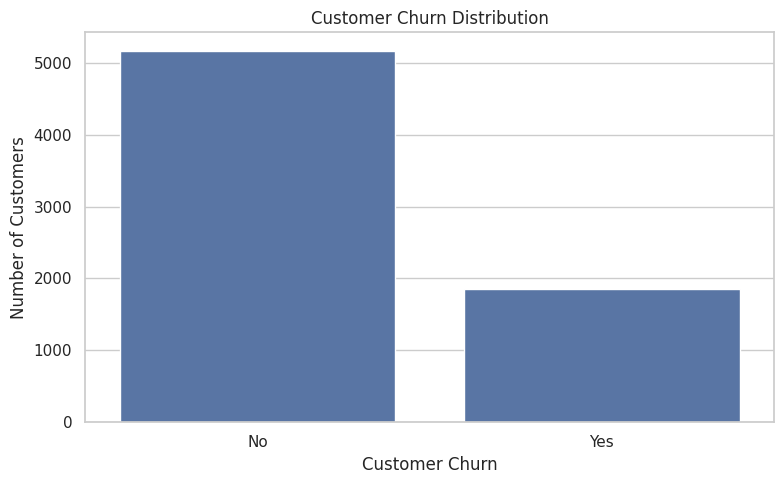

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(data=data, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

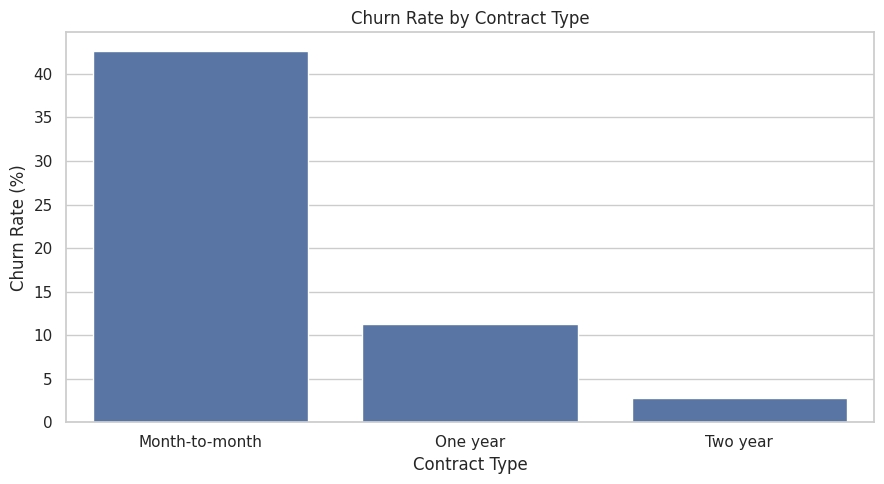

In [8]:
contract_churn = (
    data.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

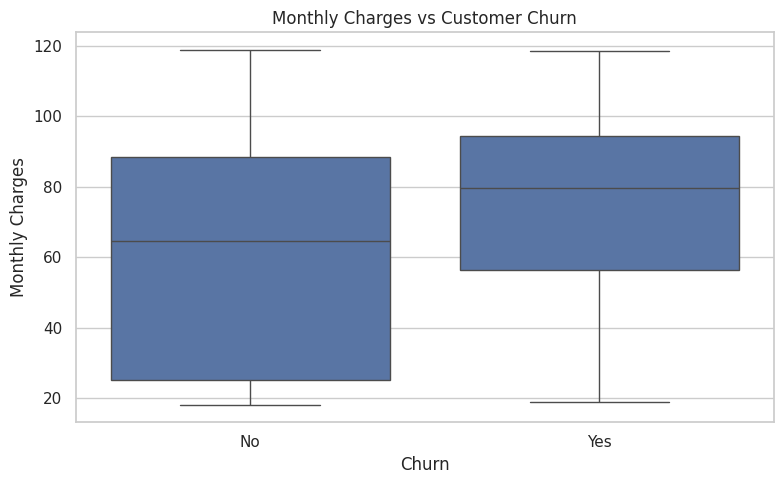

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=data,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

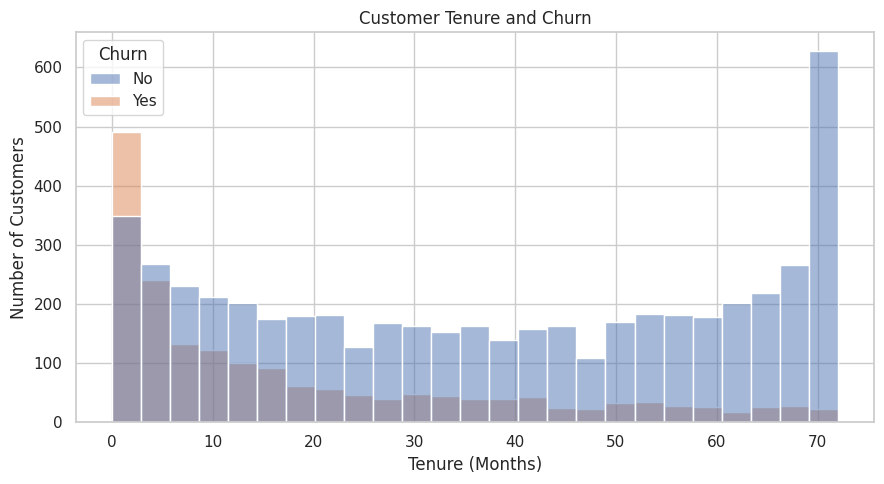

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=data,
    x="tenure",
    hue="Churn",
    bins=25,
    multiple="layer"
)

plt.title("Customer Tenure and Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [11]:
X = data.drop(columns=["Churn"])

y = data["Churn"].map({
    "No": 0,
    "Yes": 1
})

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 5616
Testing records: 1405


In [12]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing completed.")

Preprocessing completed.


In [13]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.740,0.506,0.777,0.613,0.840
1,Random Forest,0.774,0.601,0.441,0.509,0.815


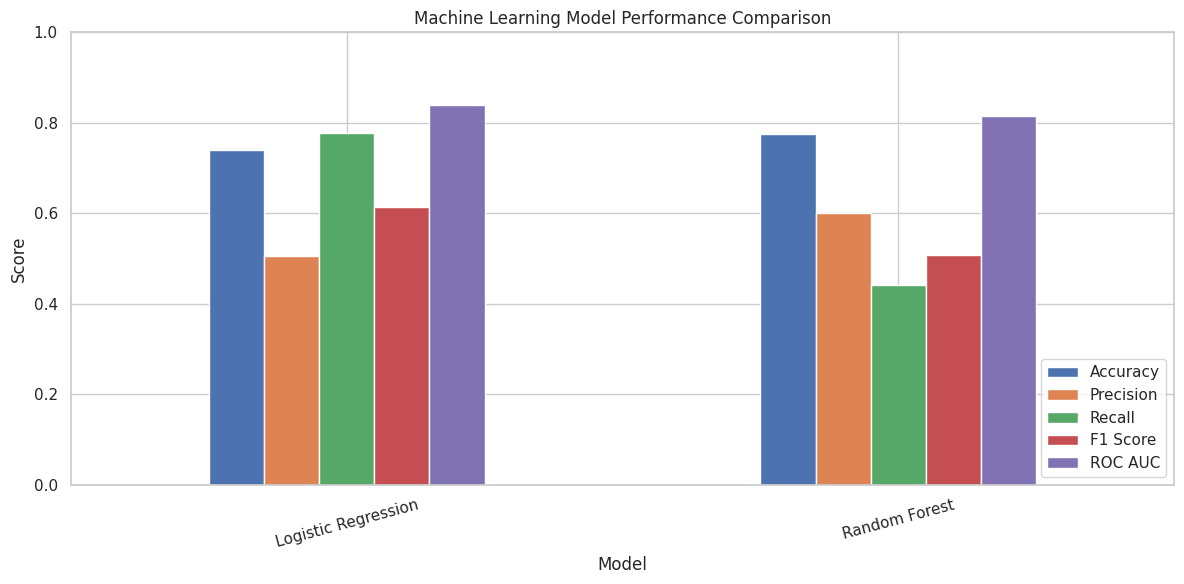

In [14]:
results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Best model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

    Retained       0.90      0.73      0.80      1033
     Churned       0.51      0.78      0.61       372

    accuracy                           0.74      1405
   macro avg       0.70      0.75      0.71      1405
weighted avg       0.80      0.74      0.75      1405



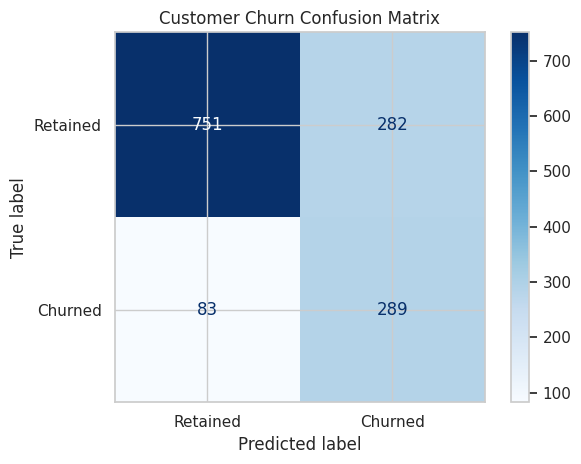

In [15]:
best_model_name = (
    results_df.sort_values("ROC AUC", ascending=False)
    .iloc[0]["Model"]
)

best_model = trained_models[best_model_name]

predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)[:, 1]

print("Best model:", best_model_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Retained", "Churned"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["Retained", "Churned"],
    cmap="Blues"
)

plt.title("Customer Churn Confusion Matrix")
plt.tight_layout()
plt.show()

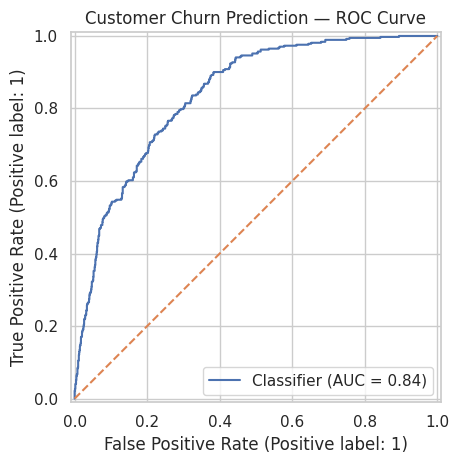

In [16]:
RocCurveDisplay.from_predictions(
    y_test,
    probabilities
)

plt.title("Customer Churn Prediction — ROC Curve")
plt.plot([0, 1], [0, 1], "--")
plt.tight_layout()
plt.show()

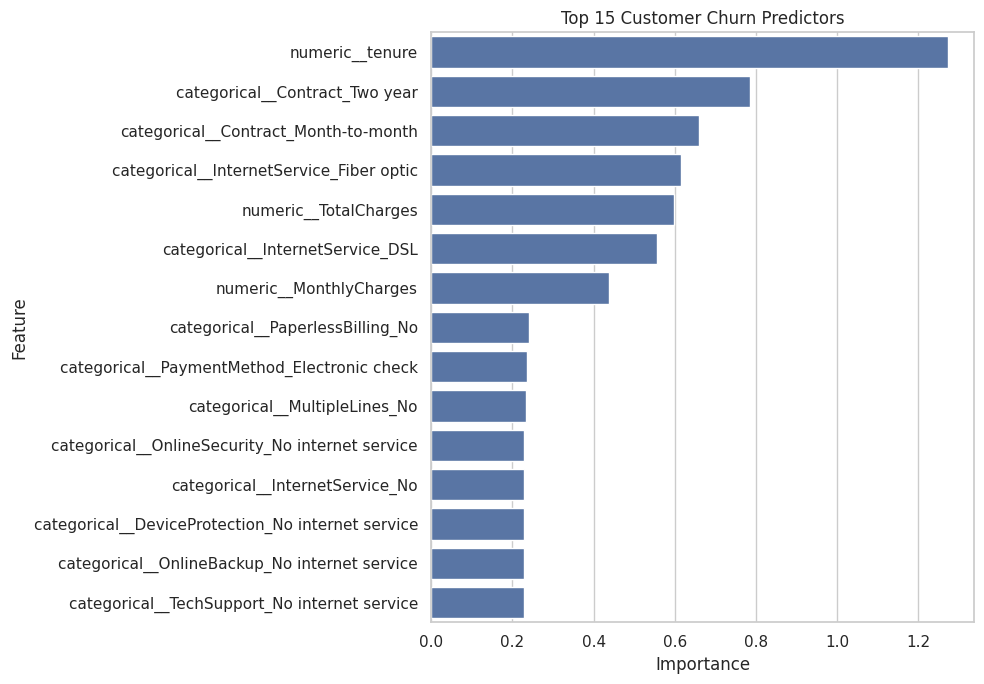

,Feature,Importance
1,numeric__tenure,1.273305
38,categorical__Contract_Two year,0.784919
36,categorical__Contract_Month-to-month,0.659609
16,categorical__InternetService_Fiber optic,0.615239
3,numeric__TotalCharges,0.597107
15,categorical__InternetService_DSL,0.555673
2,numeric__MonthlyCharges,0.437623
39,categorical__PaperlessBilling_No,0.241261
43,categorical__PaymentMethod_Electronic check,0.236098
12,categorical__MultipleLines_No,0.233310


In [17]:
model = best_model.named_steps["model"]

feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

if hasattr(model, "feature_importances_"):
    importance = model.feature_importances_
else:
    importance = np.abs(model.coef_[0])

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    "Importance", ascending=False
).head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Customer Churn Predictors")
plt.tight_layout()
plt.show()

display(importance_df)

In [18]:
total_customers = len(data)
churned_customers = (data["Churn"] == "Yes").sum()
retained_customers = (data["Churn"] == "No").sum()

churn_rate = churned_customers / total_customers * 100

print("CUSTOMER RETENTION REPORT")
print("-" * 35)
print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print("Retained customers:", retained_customers)
print(f"Overall churn rate: {churn_rate:.2f}%")

print("\nBUSINESS RECOMMENDATIONS")
print("1. Investigate contract types with high churn.")
print("2. Improve onboarding for new customers.")
print("3. Review pricing and service complaints.")
print("4. Test targeted retention offers.")
print("5. Monitor model precision and recall.")

CUSTOMER RETENTION REPORT
-----------------------------------
Total customers: 7021
Churned customers: 1857
Retained customers: 5164
Overall churn rate: 26.45%

BUSINESS RECOMMENDATIONS
1. Investigate contract types with high churn.
2. Improve onboarding for new customers.
3. Review pricing and service complaints.
4. Test targeted retention offers.
5. Monitor model precision and recall.


In [19]:
results_df.to_csv(
    "customer_churn_model_comparison.csv",
    index=False
)

predictions_df = X_test.copy()

predictions_df["Actual_Churn"] = y_test.map({
    0: "No",
    1: "Yes"
}).values

predictions_df["Predicted_Churn"] = pd.Series(
    predictions, index=X_test.index
).map({
    0: "No",
    1: "Yes"
}).values

predictions_df["Churn_Risk_Probability"] = probabilities

predictions_df.to_csv(
    "customer_churn_predictions.csv",
    index=False
)

print("Project analysis completed!")
print("Model comparison and prediction CSV files saved.")

Project analysis completed!
Model comparison and prediction CSV files saved.
